# 02 - AI Business Intelligence: Business Analysis

এই notebook-এ project-এর business প্রশ্ন পরীক্ষা করা হবে: best-selling product/family, মাসভিত্তিক sales, geography, revenue এবং anomaly detection। Store Sales dataset-এ `sales`-কে sales হিসেবে ধরা হবে—এটিকে monetary revenue বলা হবে না, কারণ সেখানে unit price নেই। Country/revenue analysis-এর জন্য Online Retail dataset ব্যবহার হবে।

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_data_dir():
    roots = [Path.cwd(), *Path.cwd().parents]
    for root in roots:
        for candidate in (root / 'dataset', root / 'notebooks' / 'dataset', root / 'ai-service' / 'notebooks'):
            if (candidate / 'train.csv').is_file() or (candidate / 'Online Retail.xlsx').is_file():
                return candidate
    raise FileNotFoundError('Expected datasets in notebooks/dataset.')

DATA_DIR = find_data_dir()
print(f'Dataset folder: {DATA_DIR}')

Dataset folder: e:\9th semi\AI Project\ai-service\notebooks\dataset


## Load Store Sales data and join reference tables

In [2]:
required_files = ['train.csv', 'stores.csv']
missing_files = [name for name in required_files if not (DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(f'Required Store Sales files are missing: {missing_files}')

train = pd.read_csv(
    DATA_DIR / 'train.csv',
    parse_dates=['date'],
    dtype={'store_nbr': 'int16', 'family': 'category', 'sales': 'float32', 'onpromotion': 'float32'},
    low_memory=False,
)
stores = pd.read_csv(DATA_DIR / 'stores.csv', dtype={'store_nbr': 'int16'})
stores['store_nbr'] = stores['store_nbr'].astype('int16')
store_sales = train.merge(stores, on='store_nbr', how='left', validate='many_to_one')

print(f'Train rows: {len(train):,}; dates: {train.date.min().date()} to {train.date.max().date()}')
print('Unmatched store rows:', int(store_sales['city'].isna().sum()) if 'city' in store_sales else 'city column unavailable')
display(store_sales.head())

Train rows: 3,000,888; dates: 2013-01-01 to 2017-08-15
Unmatched store rows: 0


,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0.0,Quito,Pichincha,D,13
1,1,2013-01-01,1,BABY CARE,0.0,0.0,Quito,Pichincha,D,13
2,2,2013-01-01,1,BEAUTY,0.0,0.0,Quito,Pichincha,D,13
3,3,2013-01-01,1,BEVERAGES,0.0,0.0,Quito,Pichincha,D,13
4,4,2013-01-01,1,BOOKS,0.0,0.0,Quito,Pichincha,D,13


## Best-selling product family and monthly sales

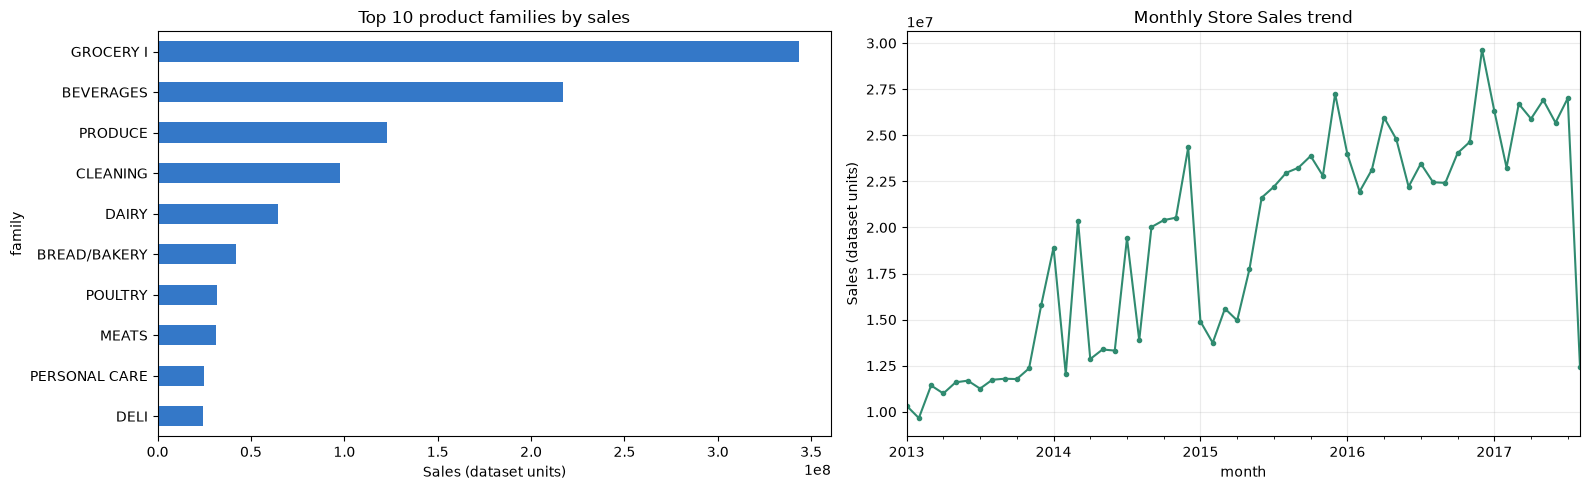

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Top 10 product families
family_sales.head(10).sort_values(
    by='total_sales',
    ascending=True
).plot.barh(
    ax=axes[0],
    color='#3478c8',
    legend=False
)

axes[0].set_title('Top 10 product families by sales')
axes[0].set_xlabel('Sales (dataset units)')

# Monthly sales trend
monthly_sales.plot(
    ax=axes[1],
    color='#308b70',
    marker='o',
    markersize=3
)

axes[1].set_title('Monthly Store Sales trend')
axes[1].set_ylabel('Sales (dataset units)')
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## Store/city performance, promotions, transactions, holidays, and oil

,,total_sales
store_nbr,city,
44,Quito,62087552.0
45,Quito,54498012.0
47,Quito,50948312.0
3,Quito,50481912.0
49,Quito,43420096.0
46,Quito,41896064.0
48,Quito,35933132.0
51,Guayaquil,32911490.0
8,Quito,30494286.0


,total_sales
city,
Quito,556741824.0
Guayaquil,122967264.0
Cuenca,49168596.0
Ambato,40304400.0
Santo Domingo,35834324.0
Machala,33386796.0
Cayambe,28325558.0
Latacunga,21182264.0
Daule,19188022.0


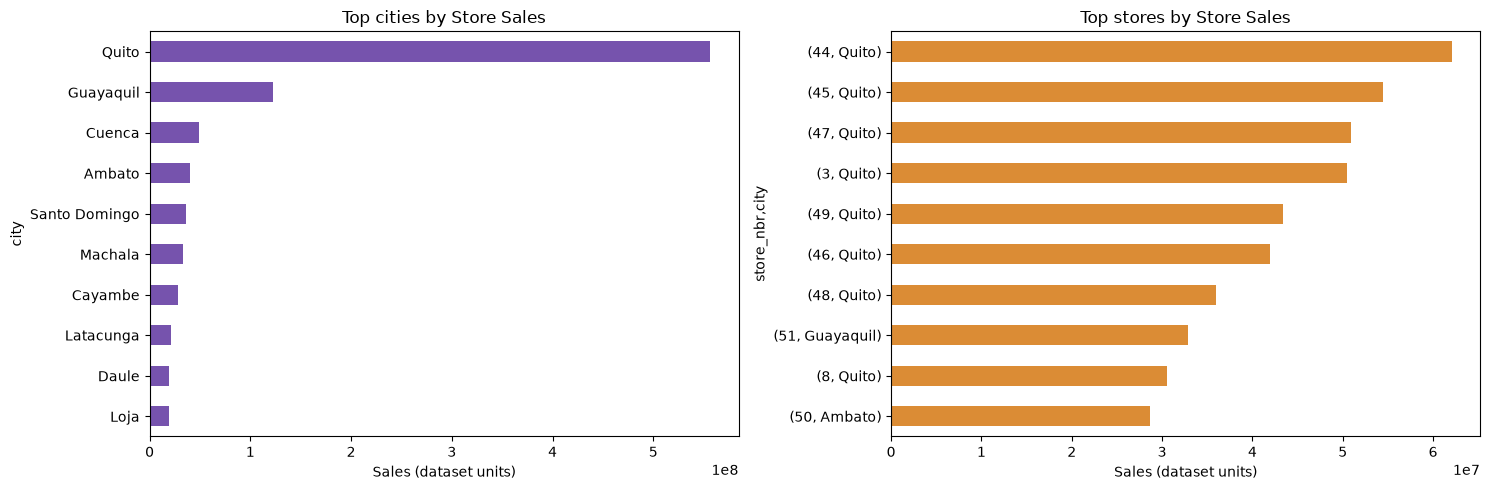

Daily sales / transactions correlation: 0.677


,Store Sales KPIs
Total sales,1.073645e+09
Train rows,3.000888e+06
Stores,5.400000e+01
Product families,3.300000e+01
Transactions (summed),1.414789e+08


Daily sales on holiday dates vs other dates (descriptive, not causal):


,count,mean,median,sum
is_holiday,,,,
False,1432,627547.6875,624853.71875,898648256.0
True,252,694431.3750,680788.37500,174996704.0


Daily sales and dcoilwtico correlation: -0.705


,date,sales,dcoilwtico
1,2013-01-02,496092.40625,93.14
2,2013-01-03,361461.25000,92.97
3,2013-01-04,354459.68750,93.12
4,2013-01-07,336122.81250,93.20
5,2013-01-08,318347.75000,93.21


In [5]:
store_totals = store_sales.groupby(['store_nbr', 'city'], dropna=False)['sales'].sum().sort_values(ascending=False)
city_totals = store_sales.groupby('city', dropna=False)['sales'].sum().sort_values(ascending=False)
display(store_totals.head(10).rename('total_sales').to_frame())
display(city_totals.head(10).rename('total_sales').to_frame())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
city_totals.head(10).sort_values().plot.barh(ax=axes[0], color='#7653ad')
axes[0].set_title('Top cities by Store Sales')
axes[0].set_xlabel('Sales (dataset units)')
store_totals.head(10).sort_values().plot.barh(ax=axes[1], color='#db8c35')
axes[1].set_title('Top stores by Store Sales')
axes[1].set_xlabel('Sales (dataset units)')
plt.tight_layout()
plt.show()

kpis = {'Total sales': train['sales'].sum(), 'Train rows': len(train),
        'Stores': train['store_nbr'].nunique(), 'Product families': train['family'].nunique()}
if (DATA_DIR / 'transactions.csv').is_file():
    transactions = pd.read_csv(DATA_DIR / 'transactions.csv', parse_dates=['date'], dtype={'store_nbr': 'int16'})
    kpis['Transactions (summed)'] = transactions['transactions'].sum()
    transactions['store_nbr'] = transactions['store_nbr'].astype('int16')
    daily_store = train.groupby('date', as_index=False)['sales'].sum()
    daily_transactions = transactions.groupby('date', as_index=False)['transactions'].sum()
    print('Daily sales / transactions correlation:',
          round(daily_store.merge(daily_transactions, on='date')['sales'].corr(
              daily_store.merge(daily_transactions, on='date')['transactions']), 3))
display(pd.DataFrame([kpis], index=['Store Sales KPIs']).T.rename(columns={0: 'value'}))

if (DATA_DIR / 'holidays_events.csv').is_file():
    holidays = pd.read_csv(DATA_DIR / 'holidays_events.csv', parse_dates=['date'])
    daily = train.groupby('date', as_index=False)['sales'].sum()
    holiday_dates = holidays[['date']].drop_duplicates().assign(is_holiday=True)
    daily = daily.merge(holiday_dates, on='date', how='left')
    daily['is_holiday'] = daily['is_holiday'].fillna(False)
    print('Daily sales on holiday dates vs other dates (descriptive, not causal):')
    display(daily.groupby('is_holiday')['sales'].agg(['count', 'mean', 'median', 'sum']))

if (DATA_DIR / 'oil.csv').is_file():
    oil = pd.read_csv(DATA_DIR / 'oil.csv', parse_dates=['date'])
    oil_column = next((column for column in oil.columns if column != 'date'), None)
    if oil_column:
        daily = train.groupby('date', as_index=False)['sales'].sum()
        oil_joined = daily.merge(oil, on='date', how='inner').dropna(subset=[oil_column])
        print(f'Daily sales and {oil_column} correlation:',
              round(oil_joined['sales'].corr(oil_joined[oil_column]), 3))
        display(oil_joined.head())

## Online Retail: best-selling products, revenue, country, and monthly trend

Revenue is calculated as `Quantity * UnitPrice`. Positive-sales revenue excludes returns/cancellations for the gross-sales KPI; net revenue retains negative lines. Inspect both before choosing a business definition.

Positive-sales revenue: 10,666,684.54
Net revenue including returns/cancellations: 9,747,747.93
Unique orders/invoices: 25,900
Return/cancellation rows (negative quantity): 10,624
Best-selling products by quantity:


,quantity_sold
Description,
"PAPER CRAFT , LITTLE BIRDIE",80995
MEDIUM CERAMIC TOP STORAGE JAR,78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047
JUMBO BAG RED RETROSPOT,48474
WHITE HANGING HEART T-LIGHT HOLDER,37891
POPCORN HOLDER,36761
ASSORTED COLOUR BIRD ORNAMENT,36461
PACK OF 72 RETROSPOT CAKE CASES,36419
RABBIT NIGHT LIGHT,30788


Highest-revenue products:


,positive_sales_revenue
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174484.74
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106292.77
PARTY BUNTING,99504.33
JUMBO BAG RED RETROSPOT,94340.05
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
Manual,78112.82
POSTAGE,78101.88


Top countries by positive-sales revenue:


,positive_sales_revenue
Country,
United Kingdom,9025222.084
Netherlands,285446.340
EIRE,283453.960
Germany,228867.140
France,209715.110
Australia,138521.310
Spain,61577.110
Switzerland,57089.900
Belgium,41196.340


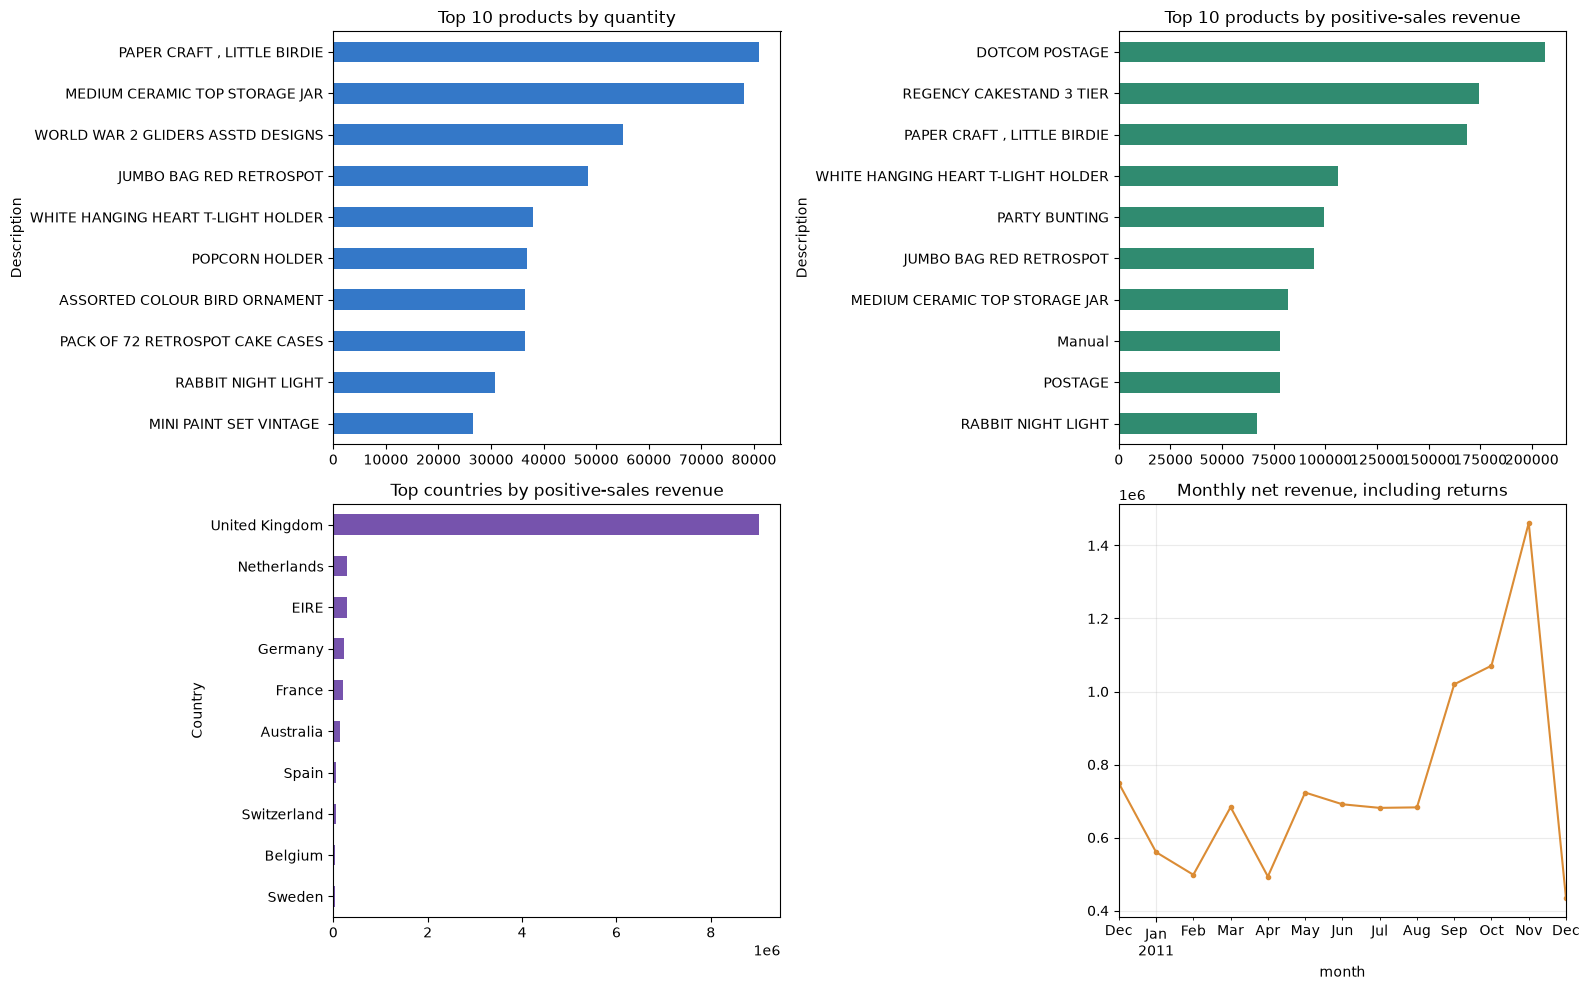

In [6]:
retail_path = DATA_DIR / 'Online Retail.xlsx'
if not retail_path.is_file():
    print('Online Retail.xlsx is missing; country and retail revenue analysis skipped.')
else:
    retail = pd.read_excel(retail_path)
    retail['InvoiceDate'] = pd.to_datetime(retail['InvoiceDate'], errors='coerce')
    retail['Quantity'] = pd.to_numeric(retail['Quantity'], errors='coerce')
    retail['UnitPrice'] = pd.to_numeric(retail['UnitPrice'], errors='coerce')
    retail['line_revenue'] = retail['Quantity'] * retail['UnitPrice']
    positive_sales = retail.loc[(retail['Quantity'] > 0) & (retail['UnitPrice'] > 0)].copy()
    product_name = 'Description' if 'Description' in retail else 'StockCode'
    best_sellers = positive_sales.groupby(product_name)['Quantity'].sum().sort_values(ascending=False)
    product_revenue = positive_sales.groupby(product_name)['line_revenue'].sum().sort_values(ascending=False)
    country_sales = positive_sales.groupby('Country')['line_revenue'].sum().sort_values(ascending=False)
    retail_monthly = (
        retail.dropna(subset=['InvoiceDate'])
        .assign(month=lambda frame: frame['InvoiceDate'].dt.to_period('M').dt.to_timestamp())
        .groupby('month')['line_revenue'].sum().sort_index()
    )
    print(f'Positive-sales revenue: {positive_sales["line_revenue"].sum():,.2f}')
    print(f'Net revenue including returns/cancellations: {retail["line_revenue"].sum():,.2f}')
    print(f'Unique orders/invoices: {retail["InvoiceNo"].nunique():,}')
    print(f'Return/cancellation rows (negative quantity): {(retail["Quantity"] < 0).sum():,}')
    print('Best-selling products by quantity:')
    display(best_sellers.head(10).rename('quantity_sold').to_frame())
    print('Highest-revenue products:')
    display(product_revenue.head(10).rename('positive_sales_revenue').to_frame())
    print('Top countries by positive-sales revenue:')
    display(country_sales.head(10).rename('positive_sales_revenue').to_frame())

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    best_sellers.head(10).sort_values().plot.barh(ax=axes[0, 0], color='#3478c8')
    axes[0, 0].set_title('Top 10 products by quantity')
    product_revenue.head(10).sort_values().plot.barh(ax=axes[0, 1], color='#308b70')
    axes[0, 1].set_title('Top 10 products by positive-sales revenue')
    country_sales.head(10).sort_values().plot.barh(ax=axes[1, 0], color='#7653ad')
    axes[1, 0].set_title('Top countries by positive-sales revenue')
    retail_monthly.plot(ax=axes[1, 1], color='#db8c35', marker='o', markersize=3)
    axes[1, 1].set_title('Monthly net revenue, including returns')
    axes[1, 1].grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

## Anomaly detection: robust rolling deviation

This is an explainable statistical baseline, not a trained AI model. It flags daily totals far from the preceding 28-day rolling median using a robust MAD score. Flags are candidates for review, not proof of fraud or business error.

Flagged Store Sales dates: 78


,actual,baseline,robust_score,is_anomaly
date,,,,
2013-06-02,6.376985e+05,331367.625000,8.316572,True
2014-03-01,9.113602e+05,397880.515625,8.268486,True
2016-04-03,1.266908e+06,679328.281250,6.777038,True
2015-01-01,1.277362e+04,790233.125000,-6.681452,True
2016-04-18,1.345921e+06,690098.500000,6.489189,True
2015-05-31,1.023565e+06,500797.281250,6.418632,True
2013-06-01,5.669018e+05,331367.625000,6.394514,True
2017-05-01,1.306699e+06,786460.781250,6.328351,True
2013-09-01,6.404062e+05,350420.671875,6.072884,True


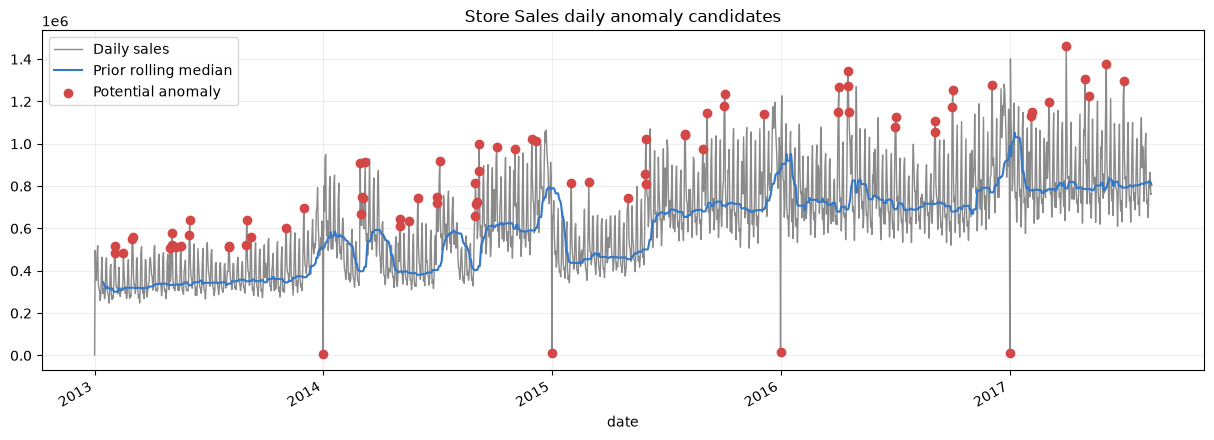

Flagged Online Retail dates: 8


,actual,baseline,robust_score,is_anomaly
InvoiceDate,,,,
2011-03-29,70531.47,21943.880,8.660706,True
2011-05-10,45564.12,24732.400,3.678425,True
2011-05-12,59911.97,25357.405,4.988860,True
2011-05-17,53603.83,25825.495,3.871727,True
2011-08-04,61028.65,26377.890,4.134921,True
2011-08-11,72132.79,25730.245,5.720887,True
2011-09-20,109286.21,28545.965,6.472843,True
2011-11-14,112141.11,43775.120,4.733228,True


In [7]:
def detect_rolling_anomalies(daily_series, window=28, threshold=3.5):
    values = daily_series.astype(float).sort_index()
    prior = values.shift(1)
    baseline = prior.rolling(window=window, min_periods=max(7, window // 2)).median()
    mad = prior.rolling(window=window, min_periods=max(7, window // 2)).apply(
        lambda sample: np.median(np.abs(sample - np.median(sample))), raw=True
    )
    score = 0.6745 * (values - baseline) / mad.replace(0, np.nan)
    result = pd.DataFrame({'actual': values, 'baseline': baseline, 'robust_score': score})
    result['is_anomaly'] = result['robust_score'].abs() > threshold
    return result

store_daily_sales = train.groupby('date')['sales'].sum().sort_index()
store_anomalies = detect_rolling_anomalies(store_daily_sales)
print('Flagged Store Sales dates:', int(store_anomalies['is_anomaly'].sum()))
display(store_anomalies.loc[store_anomalies['is_anomaly']].sort_values(
    'robust_score', key=lambda values: values.abs(), ascending=False
).head(20))

fig, ax = plt.subplots(figsize=(15, 5))
store_anomalies['actual'].plot(ax=ax, color='#8a8a8a', linewidth=1, label='Daily sales')
store_anomalies['baseline'].plot(ax=ax, color='#3478c8', linewidth=1.5, label='Prior rolling median')
flagged = store_anomalies.loc[store_anomalies['is_anomaly']]
ax.scatter(flagged.index, flagged['actual'], color='#d44747', label='Potential anomaly', zorder=3)
ax.set_title('Store Sales daily anomaly candidates')
ax.legend()
ax.grid(alpha=0.2)
plt.show()

if 'retail' in globals():
    retail_daily = retail.dropna(subset=['InvoiceDate']).groupby(
        retail['InvoiceDate'].dt.floor('D')
    )['line_revenue'].sum().sort_index()
    retail_anomalies = detect_rolling_anomalies(retail_daily)
    print('Flagged Online Retail dates:', int(retail_anomalies['is_anomaly'].sum()))
    display(retail_anomalies.loc[retail_anomalies['is_anomaly']].head(20))

## Feature checklist

- Best-selling product: Online Retail product description/stock code and Store Sales product family.
- Monthly sales: Store Sales monthly totals and Online Retail monthly net revenue.
- Country-wise sales: Online Retail only; Store Sales supports city/state/store analysis.
- Revenue: Online Retail only, with positive-sales and net-of-returns figures distinguished.
- Sales forecasting: tested separately in `03_sales_forecasting.ipynb`.
- Anomaly detection: rolling robust statistical baseline above.